# Bank customer churn — EDA

Exploratory analysis of `train.csv` (15,000 customers, binary target `Exited`).
Only aggregated charts and tables are shown: the data is for learning only and no raw rows are displayed.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "../components")
from config import FEATURES, RAW_DIR_LOCAL, TARGET

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

IMG_DIR = Path("../docs/img/eda")
IMG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(f"../{RAW_DIR_LOCAL}/train.csv")
print(f"rows: {len(df):,}  columns: {df.shape[1]}  missing values: {int(df.isna().sum().sum())}")

rows: 15,000  columns: 14  missing values: 0


## Target balance

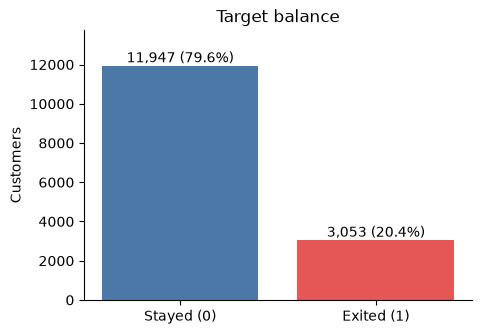

positive rate: 0.2035


In [2]:
counts = df[TARGET].value_counts().sort_index()
rate = df[TARGET].mean()

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Stayed (0)", "Exited (1)"], counts.values, color=["#4c78a8", "#e45756"])
ax.bar_label(bars, labels=[f"{c:,} ({c / len(df):.1%})" for c in counts.values])
ax.set_ylabel("Customers")
ax.set_title("Target balance")
ax.set_ylim(0, counts.max() * 1.15)
plt.show()
print(f"positive rate: {rate:.4f}")

**Reading:** about 20.4% of customers exited, so the classes are imbalanced (roughly 4 to 1) but not extreme.
Accuracy would be misleading here (always predicting "stayed" scores about 80%), which is why the project uses ROC-AUC.
Stratified splits are needed so every fold keeps this rate.

## Numeric distributions

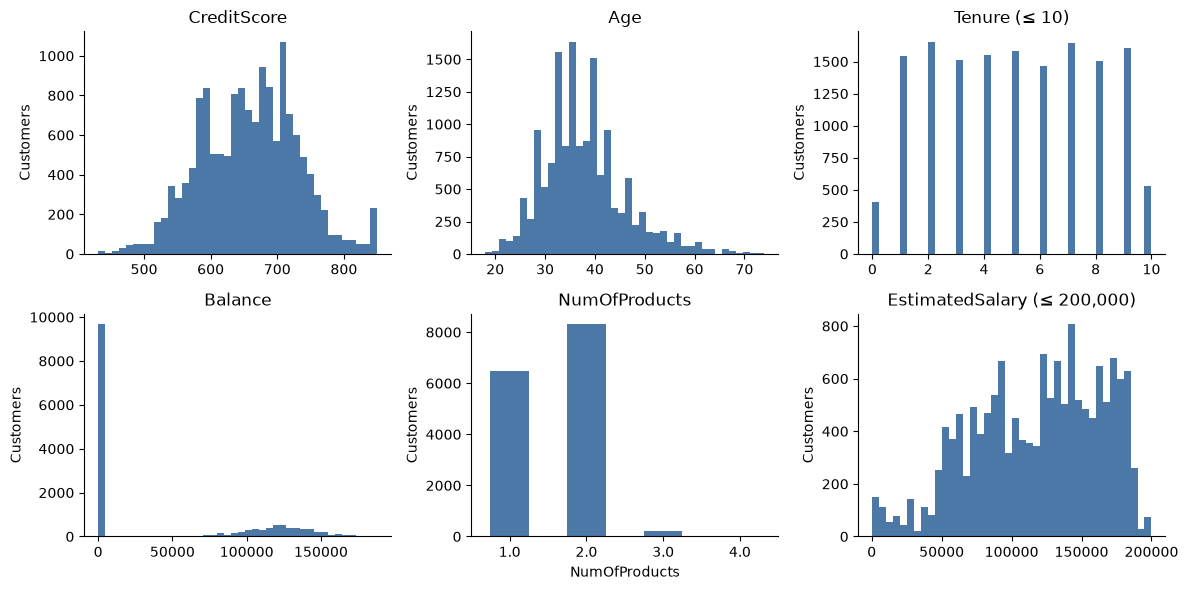

      CreditScore   Age  Tenure   Balance  NumOfProducts  EstimatedSalary
mean        658.5  37.7     5.0   43365.4            1.6         119749.2
std          73.3   8.1     2.8   59914.9            0.5         161833.5
min         431.0  18.0     0.0       0.0            1.0            479.5
50%         661.0  37.0     5.0       0.0            2.0         124045.6
max         850.0  74.0    30.0  187842.0            4.0       18171718.7

Balance == 0: 64.4%
EstimatedSalary > 200,000: 2 rows


In [3]:
numeric = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
salary_cap = 200_000

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), numeric):
    s = df[col]
    if col == "EstimatedSalary":
        s = s[s <= salary_cap]
        ax.set_title(f"{col} (≤ {salary_cap:,})")
    elif col == "Tenure":
        s = s[s <= 10]
        ax.set_title(f"{col} (≤ 10)")
    else:
        ax.set_title(col)
    if col == "NumOfProducts":
        s.value_counts().sort_index().plot.bar(ax=ax, color="#4c78a8", rot=0)
    else:
        ax.hist(s, bins=40, color="#4c78a8")
    ax.set_ylabel("Customers")
fig.tight_layout()
plt.show()

print(df[numeric].describe().loc[["mean", "std", "min", "50%", "max"]].round(1).to_string())
print(f"\nBalance == 0: {(df['Balance'] == 0).mean():.1%}")
print(f"EstimatedSalary > {salary_cap:,}: {(df['EstimatedSalary'] > salary_cap).sum()} rows")

**Reading:**

- `CreditScore` is roughly bell-shaped (mean 658, range 431–850), with a pile-up at the 850 cap.
- `Age` is right-skewed (mean 37.7, median 37, max 74): most customers are between 32 and 42.
- `Balance` is bimodal: 64.4% of customers have exactly zero, and the rest are centred near 122k. A "zero balance" flag will probably carry signal that the raw value hides.
- `NumOfProducts` is almost all 1 or 2 (98.5% of customers); 3 and 4 are rare.
- `EstimatedSalary` is spread between about 50k and 190k, with a thinner tail below 50k, but 2 rows are around 18M. They are clearly data errors, so the chart is capped at 200k (and `Tenure` at 10 for the one row at 30). They inflate the overall std to 161k and would distort a scaler, so they matter for preprocessing.
- `Tenure` ranges from 0 to 10, apart from one row at 30.

## Churn rate by segment

In [4]:
overall = df[TARGET].mean()


def churn_by(groups, title, filename=None, rot=0):
    # Bar chart of the churn rate per group; the table below lists the group sizes.
    stats = df.groupby(groups, observed=True)[TARGET].agg(rate="mean", customers="size")
    fig, ax = plt.subplots(figsize=(6, 3.8))
    bars = ax.bar(stats.index.astype(str), stats["rate"], color="#4c78a8")
    ax.bar_label(bars, labels=[f"{r:.1%}" for r in stats["rate"]])
    ax.axhline(overall, color="#e45756", linestyle="--", linewidth=1, label=f"overall {overall:.1%}")
    ax.set_ylabel("Churn rate")
    ax.set_title(title)
    ax.set_ylim(0, min(1.1, stats["rate"].max() * 1.2))
    ax.tick_params(axis="x", rotation=rot)
    ax.legend(frameon=False)
    if filename:
        fig.savefig(IMG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(stats.assign(rate=stats["rate"].round(4)).to_string())

### Geography

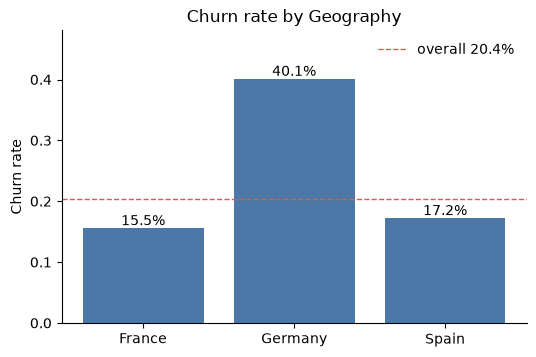

             rate  customers
Geography                   
France     0.1552       9060
Germany    0.4007       2738
Spain      0.1718       3202


In [5]:
churn_by("Geography", "Churn rate by Geography")

**Reading:** Germany stands out with a 40.1% churn rate, against 15.5% in France and 17.2% in Spain, even though it holds only 18% of the customers (2,738 rows).
France and Spain sit close to the overall 20.4%, so the signal is "Germany or not". The model needs `Geography` as a feature.

### Gender

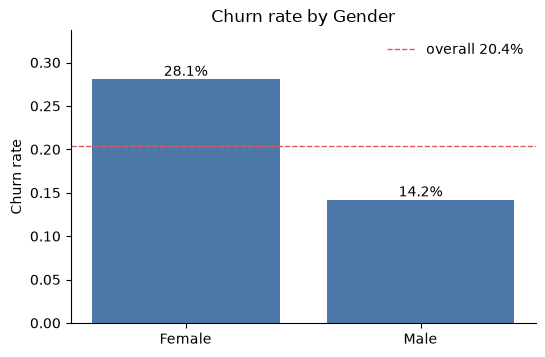

          rate  customers
Gender                   
Female  0.2809       6643
Male    0.1420       8357


In [6]:
churn_by("Gender", "Churn rate by Gender", "churn-by-gender.png")

**Reading:** women churn at 28.1% and men at 14.2%, about twice as often, with a reasonably balanced split (6,643 against 8,357 customers).
It is a strong and clean signal for a two-valued feature.

### Age band

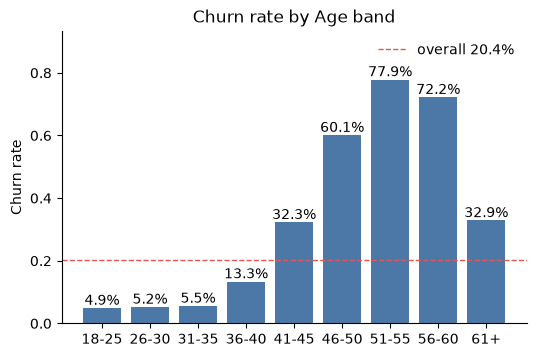

           rate  customers
AgeBand                   
18-25    0.0488        574
26-30    0.0523       1988
31-35    0.0553       3939
36-40    0.1334       4002
41-45    0.3226       2232
46-50    0.6009       1125
51-55    0.7785        596
56-60    0.7221        331
61+      0.3286        213


In [7]:
df["AgeBand"] = pd.cut(
    df["Age"],
    bins=[17, 25, 30, 35, 40, 45, 50, 55, 60, 100],
    labels=["18-25", "26-30", "31-35", "36-40", "41-45", "46-50", "51-55", "56-60", "61+"],
)
churn_by("AgeBand", "Churn rate by Age band", "churn-by-age-band.png")

**Reading:** age is the strongest single feature so far, and the relation is not monotonic.
Churn is flat at about 5% up to age 35, then climbs to 13.3% (36-40), 32.3% (41-45), 60.1% (46-50) and peaks at 77.9% in 51-55.
It falls back to 32.9% for customers over 60, although that band is small (213 rows).
A linear model sees only part of this shape, so tree-based models or an age transform could do better; that belongs to E2.

### Number of products

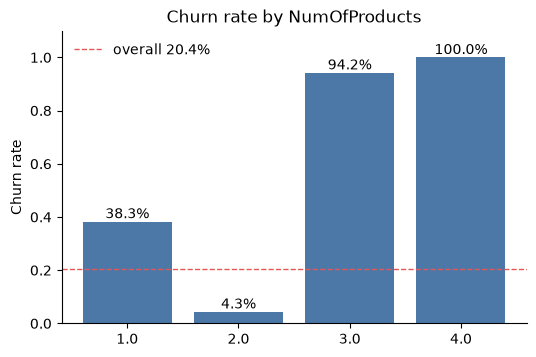

                 rate  customers
NumOfProducts                   
1.0            0.3828       6473
2.0            0.0435       8301
3.0            0.9423        208
4.0            1.0000         18


In [8]:
churn_by("NumOfProducts", "Churn rate by NumOfProducts", "churn-by-num-of-products.png")

**Reading:** this is also strongly non-linear.
Customers with 2 products almost never leave (4.3%, the biggest group with 8,301 rows), those with 1 product leave at 38.3%, and those with 3 or 4 products leave at 94.2% and 100%.
The last two groups are tiny (208 and 18 rows), so their rates are noisy, but the direction is clear.
Treating `NumOfProducts` as a plain number would blur the "exactly 2" effect.

### Active member

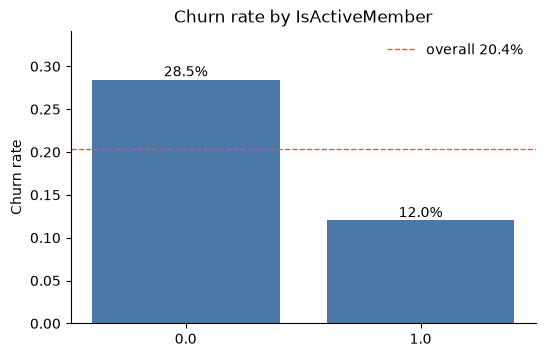

                  rate  customers
IsActiveMember                   
0.0             0.2845       7605
1.0             0.1202       7395


In [9]:
churn_by("IsActiveMember", "Churn rate by IsActiveMember", "churn-by-is-active-member.png")

**Reading:** inactive members churn at 28.5% and active ones at 12.0%, so being inactive is worth more than doubling the risk.
Both groups are large (7,605 and 7,395 rows), which makes this a stable signal.

### Zero balance

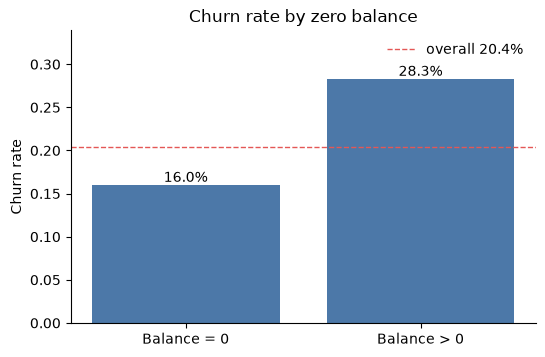

               rate  customers
ZeroBalance                   
Balance = 0  0.1598       9663
Balance > 0  0.2827       5337


In [10]:
df["ZeroBalance"] = df["Balance"] == 0
df["ZeroBalance"] = df["ZeroBalance"].map({True: "Balance = 0", False: "Balance > 0"})
churn_by("ZeroBalance", "Churn rate by zero balance")

**Reading:** customers with a positive balance churn at 28.3% against 16.0% for those with zero, a gap of about 12 points.
Before trusting it, the next chart checks whether it is just Geography in disguise.

### Geography and zero balance together

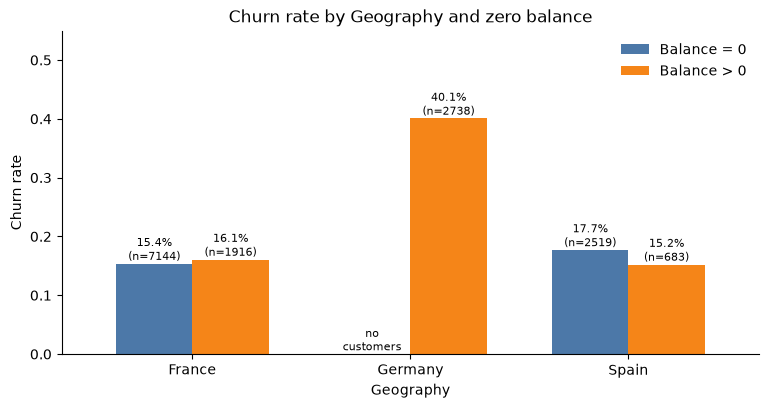

In [11]:
rates = df.groupby(["Geography", "ZeroBalance"])[TARGET].mean().unstack()
sizes = df.groupby(["Geography", "ZeroBalance"]).size().unstack()

fig, ax = plt.subplots(figsize=(9, 4.2))
rates.plot.bar(ax=ax, rot=0, width=0.7, color=["#4c78a8", "#f58518"])
for container, col in zip(ax.containers, rates.columns):
    labels = [f"{r:.1%}\n(n={int(n)})" if pd.notna(r) else "no\ncustomers" for r, n in zip(rates[col], sizes[col].fillna(0))]
    ax.bar_label(container, labels=labels, fontsize=8)
ax.set_ylabel("Churn rate")
ax.set_title("Churn rate by Geography and zero balance")
ax.set_ylim(0, 0.55)
ax.legend(title=None, frameon=False)
fig.savefig(IMG_DIR / "churn-by-geography-and-zero-balance.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading:** the zero-balance effect disappears once Geography is fixed.
Every German customer has a positive balance (2,738 rows, none with zero), while about 79% of French and Spanish customers have zero.
Inside France the churn rate is 15.4% with zero balance and 16.1% with a positive one, and inside Spain it is 17.7% and 15.2%: no consistent gap.
The 12-point gap seen before comes from Germany's 40.1% churn, so `Balance` mostly acts as a proxy for Geography here.

## Weaker features

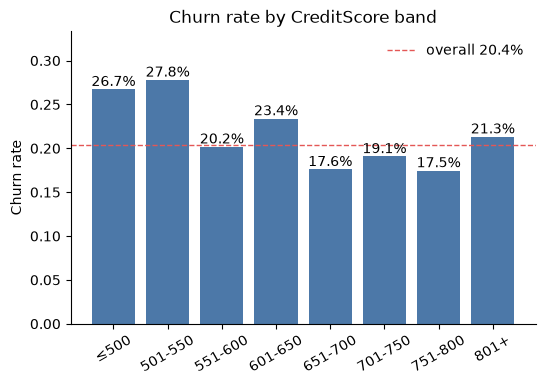

                   rate  customers
CreditScoreBand                   
≤500             0.2673        202
501-550          0.2780        831
551-600          0.2018       2691
601-650          0.2339       3074
651-700          0.1760       3664
701-750          0.1907       3130
751-800          0.1747        939
801+             0.2132        469


In [12]:
df["CreditScoreBand"] = pd.cut(df["CreditScore"], bins=[0, 500, 550, 600, 650, 700, 750, 800, 851],
                               labels=["≤500", "501-550", "551-600", "601-650", "651-700", "701-750", "751-800", "801+"])
churn_by("CreditScoreBand", "Churn rate by CreditScore band", rot=30)

**Reading:** credit score has only a weak relation with churn.
The lowest bands (500 or less, 501-550) churn at 26.7% and 27.8%, above the overall 20.4%, and the other bands stay between 17.5% and 23.4% with no clean trend.
The highest band (801+) goes back up to 21.3%, so the relation is not monotonic either.

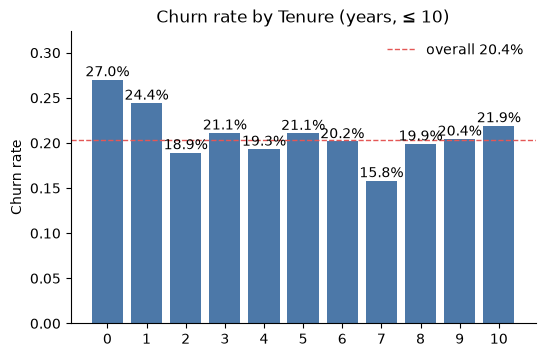

               rate  customers
TenureYears                   
0            0.2703        407
1            0.2443       1543
2            0.1894       1653
3            0.2112       1515
4            0.1933       1552
5            0.2109       1584
6            0.2016       1468
7            0.1583       1642
8            0.1991       1502
9            0.2045       1604
10           0.2193        529


In [13]:
df["TenureYears"] = df["Tenure"].where(df["Tenure"] <= 10).astype("Int64")  # drops the single row at 30
churn_by("TenureYears", "Churn rate by Tenure (years, ≤ 10)")

**Reading:** tenure is nearly flat.
Customers in their first year (tenure 0) churn at 27.0% and those with 1 year at 24.4%, and every other year stays between 15.8% and 21.9%.
It may be useful for tree models, but it will not carry much signal on its own.

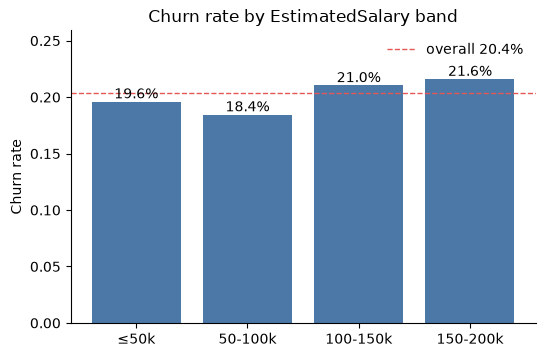

              rate  customers
SalaryBand                   
≤50k        0.1960       1046
50-100k     0.1845       4347
100-150k    0.2104       5243
150-200k    0.2160       4362


In [14]:
df["SalaryBand"] = pd.cut(df["EstimatedSalary"], bins=[0, 50_000, 100_000, 150_000, 200_000],
                          labels=["≤50k", "50-100k", "100-150k", "150-200k"])  # the 2 outliers fall outside
churn_by("SalaryBand", "Churn rate by EstimatedSalary band")

**Reading:** salary has almost no effect: the four bands sit between 18.4% and 21.6%, all close to the overall rate.
The slight rise at higher salaries is small compared with Age or NumOfProducts.

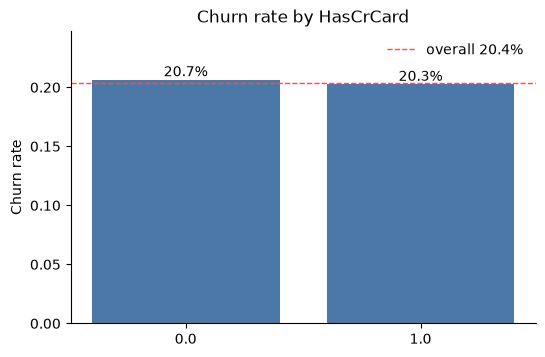

             rate  customers
HasCrCard                   
0.0        0.2066       3292
1.0        0.2027      11708


In [15]:
churn_by("HasCrCard", "Churn rate by HasCrCard")

**Reading:** having a credit card makes no difference: 20.7% without it and 20.3% with it.
`HasCrCard` looks like the least informative feature in the set.

## Features against the target

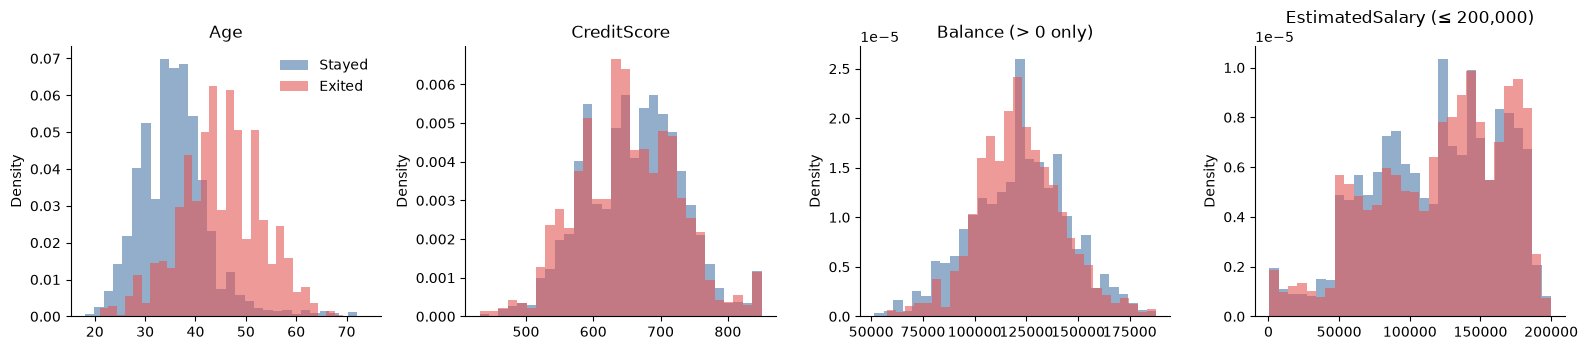

         Age  CreditScore
Exited                   
Stayed  35.0        663.0
Exited  45.0        648.0


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
panels = [
    ("Age", df["Age"]),
    ("CreditScore", df["CreditScore"]),
    ("Balance (> 0 only)", df.loc[df["Balance"] > 0, "Balance"]),
    ("EstimatedSalary (≤ 200,000)", df.loc[df["EstimatedSalary"] <= 200_000, "EstimatedSalary"]),
]
for ax, (name, values) in zip(axes, panels):
    for label, color in [(0, "#4c78a8"), (1, "#e45756")]:
        ax.hist(values[df.loc[values.index, TARGET] == label], bins=30, density=True, alpha=0.6,
                color=color, label="Exited" if label else "Stayed")
    ax.set_title(name)
    ax.set_ylabel("Density")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

print(df.groupby(TARGET)[["Age", "CreditScore"]].median().rename(index={0: "Stayed", 1: "Exited"}).to_string())

**Reading:** the distributions confirm the segment charts.
`Age` is the only one with clearly separated curves: the median is 45 for customers who exited against 35 for those who stayed.
`CreditScore` shifts by a small amount (median 648 against 663), and `Balance` (positive values only) and `EstimatedSalary` overlap almost completely.

## Correlation matrix

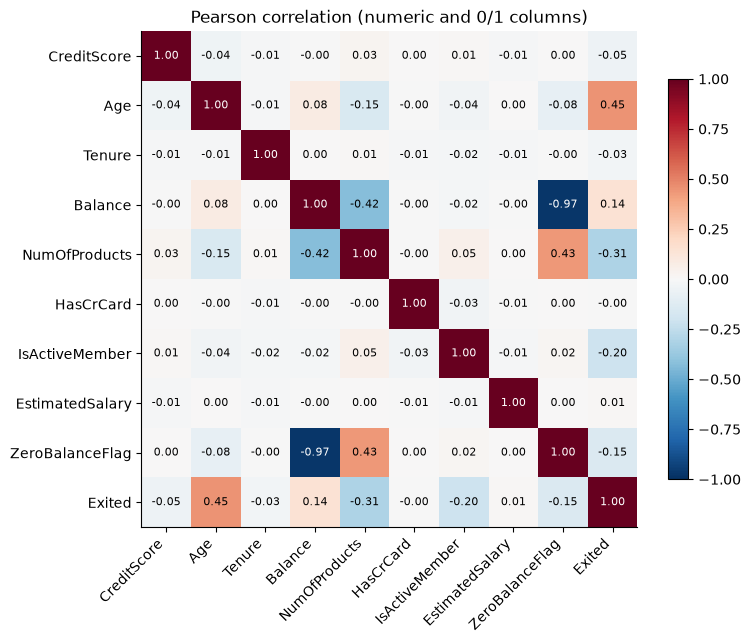

Age                0.452
NumOfProducts     -0.307
IsActiveMember    -0.204
ZeroBalanceFlag   -0.146
Balance            0.142
CreditScore       -0.047
Tenure            -0.027
EstimatedSalary    0.008
HasCrCard         -0.004


In [17]:
corr_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard",
             "IsActiveMember", "EstimatedSalary", "ZeroBalanceFlag", TARGET]
corr_df = df.assign(ZeroBalanceFlag=(df["Balance"] == 0).astype(int))[corr_cols]
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Pearson correlation (numeric and 0/1 columns)")
fig.savefig(IMG_DIR / "correlation-matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

**Reading:** the ranking against `Exited` matches the segment charts.
`Age` (0.45), `NumOfProducts` (-0.31) and `IsActiveMember` (-0.20) have the largest linear correlations, followed by `Balance` (0.14).
`CreditScore`, `Tenure`, `HasCrCard` and `EstimatedSalary` are all below 0.05 in absolute value.
Among the features, the strongest pairs are `Balance` and the zero-balance flag (-0.97, the same information) and `Balance` and `NumOfProducts` (-0.42).
So `Balance` and its flag should not both go into a linear model.
Pearson only captures linear effects: the non-monotonic shapes of Age and NumOfProducts mean their real importance is higher than these coefficients show.
Geography and Gender are categorical and do not appear here; their effect is in the segment charts.